In [1]:
import os
import pydicom
import SimpleITK as sitk
import cv2
import numpy as np
import os
import matplotlib.pyplot as plt
import nibabel as nib

In [2]:
hgucegxi_dir=r"Dataset\DICOMs\HGUCEGXI"
files = os.listdir(hgucegxi_dir)
files[:5]

['I1000000', 'I1000001', 'I1010000', 'I1020000', 'I1030000']

In [3]:
# convert entire dicom series to nifti including metadata
def convert_to_nifti(dicom_dir, nifti_dir):
    reader = sitk.ImageSeriesReader()
    dicom_names = reader.GetGDCMSeriesFileNames(dicom_dir)
    reader.SetFileNames(dicom_names)
    image = reader.Execute()
    sitk.WriteImage(image, nifti_dir)
    
# convert_to_nifti(hgucegxi_dir, r"Dataset\NIFTIs\HGUCEGXI.nii")

In [4]:
sitk_image = sitk.ReadImage(r'Dataset\NIFTIs\HGUCEGXI.nii')

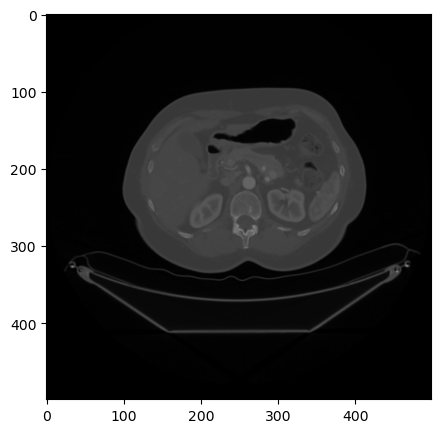

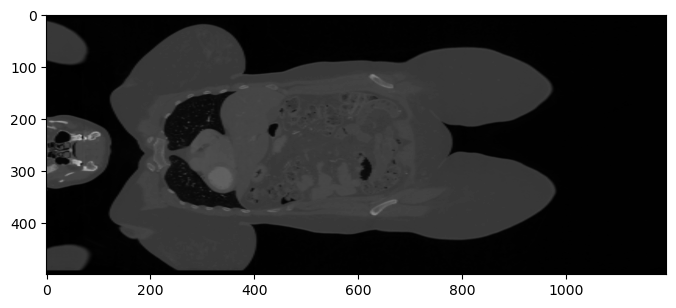

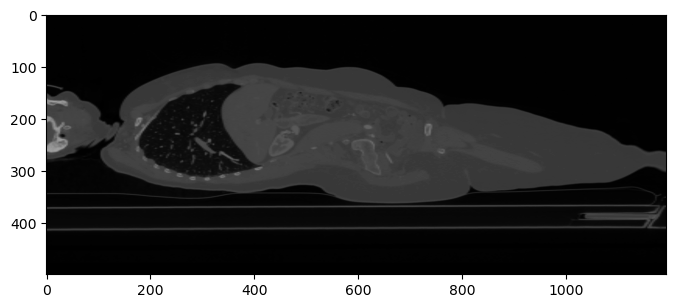

In [5]:
def get_slices(image_3d, x, y, z):
    spacing = (np.array(sitk_image.GetSpacing()[::-1])*image_3d.shape).astype(int)
    
    x_img = cv2.resize(image_3d[x, :, :].astype(float), spacing[:0:-1])
    y_img = cv2.rotate(cv2.resize(image_3d[:, y, :].astype(float), spacing[::-2]), cv2.ROTATE_90_CLOCKWISE)
    z_img = cv2.rotate(cv2.resize(image_3d[:, :, z].astype(float), spacing[:2][::-1]), cv2.ROTATE_90_CLOCKWISE)
    return x_img, y_img, z_img

temp=get_slices(sitk.GetArrayFromImage(sitk_image), 250, 180, 215)

plt.figure(figsize=(8, 5))
plt.imshow(temp[0], cmap='gray', vmin=-1024, vmax=3071)

plt.show()
plt.figure(figsize=(8, 5))
plt.imshow(temp[1], cmap='gray', vmin=-1024, vmax=3071)
plt.show()
plt.figure(figsize=(8, 8))
plt.imshow(temp[2], cmap='gray', vmin=-1024, vmax=3071)
plt.show()

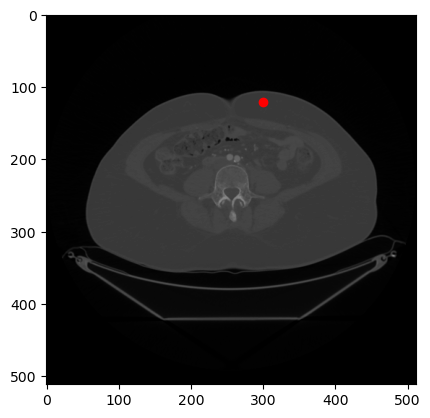

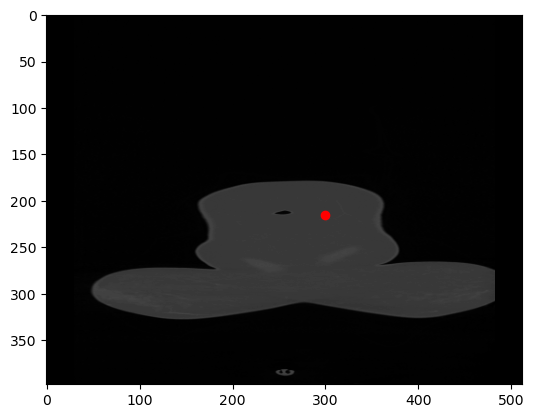

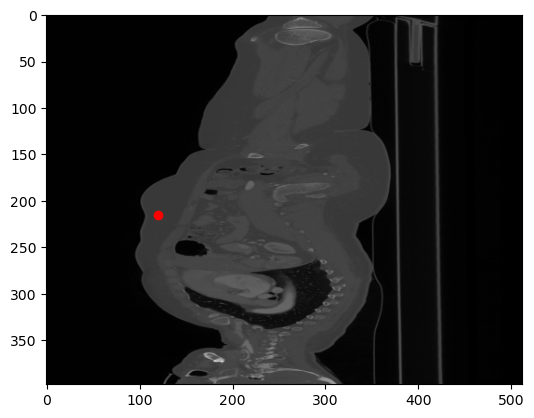

In [6]:
seed = (215, 120, 300)

temp=sitk.GetArrayFromImage(sitk_image)
plt.imshow(temp[seed[0],:,:], cmap='gray', vmin=-1024, vmax=3071)
plt.scatter(seed[2], seed[1], c='r')
plt.show()

plt.imshow(temp[:,seed[1],:], cmap='gray', vmin=-1024, vmax=3071)
plt.scatter(seed[2], seed[0], c='r')
plt.show()

plt.imshow(temp[:,:,seed[2]], cmap='gray', vmin=-1024, vmax=3071)
plt.scatter(seed[1], seed[0], c='r')
plt.show()


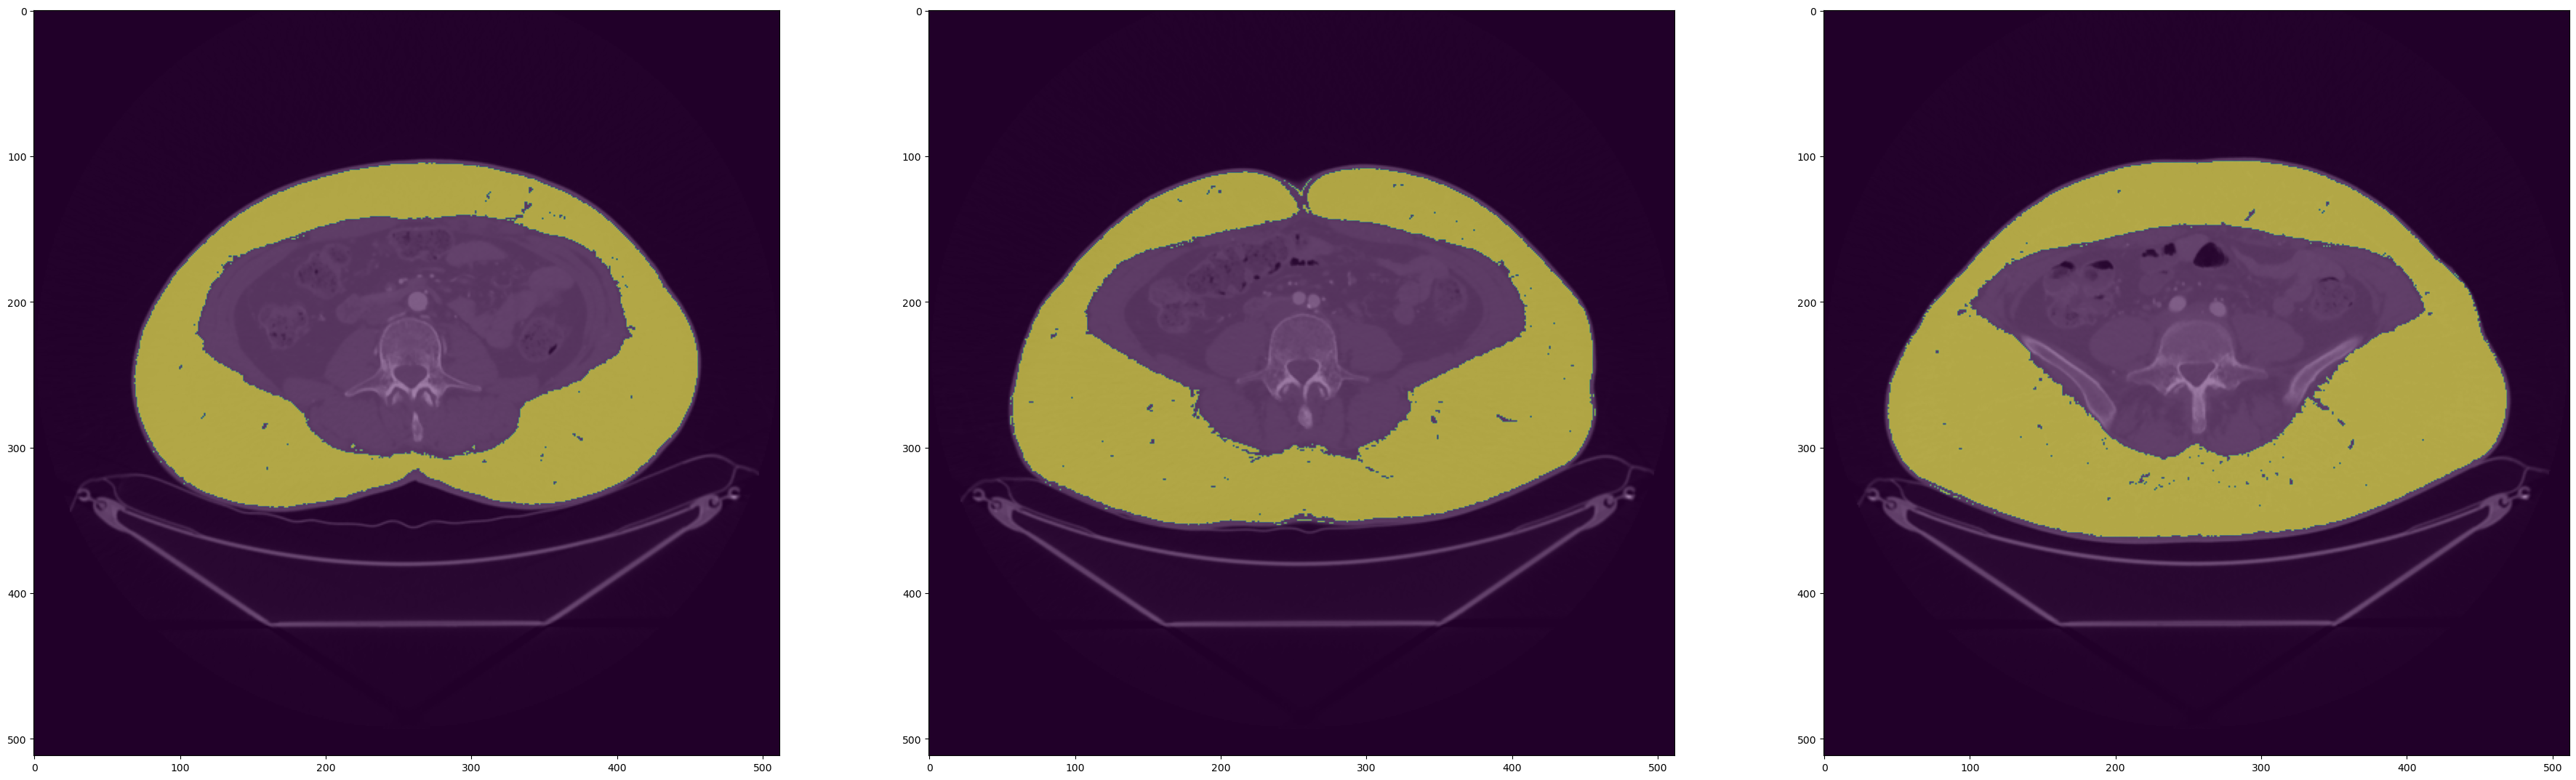

In [22]:
def get_region_grown(sitk_image, seed, r,d=False):
    # get average value of the seed
    temp=sitk.GetArrayFromImage(sitk_image)
    seed_value=np.mean([ temp[*(seed+np.array(i))]
                        for i in [[0,0,0], [0,0,1], [0,1,0], [0,1,1], [1,0,0], [1,0,1], [1,1,0], [1,1,1]]])
    seg_con = sitk.ConnectedThreshold(sitk_image, seedList=[seed], lower=seed_value-r, upper=seed_value+r)

    temp=sitk.GetArrayFromImage(seg_con)
    if d:
        temp=cv2.dilate(temp.astype(np.uint8), np.array([[0,1,0],[1,1,1],[0,1,0]]).astype(np.uint8), iterations=3)
    return temp

sitk_image = sitk.ReadImage(r'Dataset\NIFTIs\HGUCEGXI.nii')
temp=get_region_grown(sitk_image, seed, 18, True) * get_region_grown(sitk_image, seed, 40)

fig,ax = plt.subplots(1, 3, figsize=(15*3, 15))
ax[0].imshow(sitk.GetArrayFromImage(sitk_image)[seed[0]+10], cmap='gray') 
ax[0].imshow(temp[seed[0]+10], alpha=0.5)

ax[1].imshow(sitk.GetArrayFromImage(sitk_image)[seed[0]], cmap='gray')
ax[1].imshow(temp[seed[0]], alpha=0.5)

ax[2].imshow(sitk.GetArrayFromImage(sitk_image)[seed[0]-10], cmap='gray')
ax[2].imshow(temp[seed[0]-10], alpha=0.5)

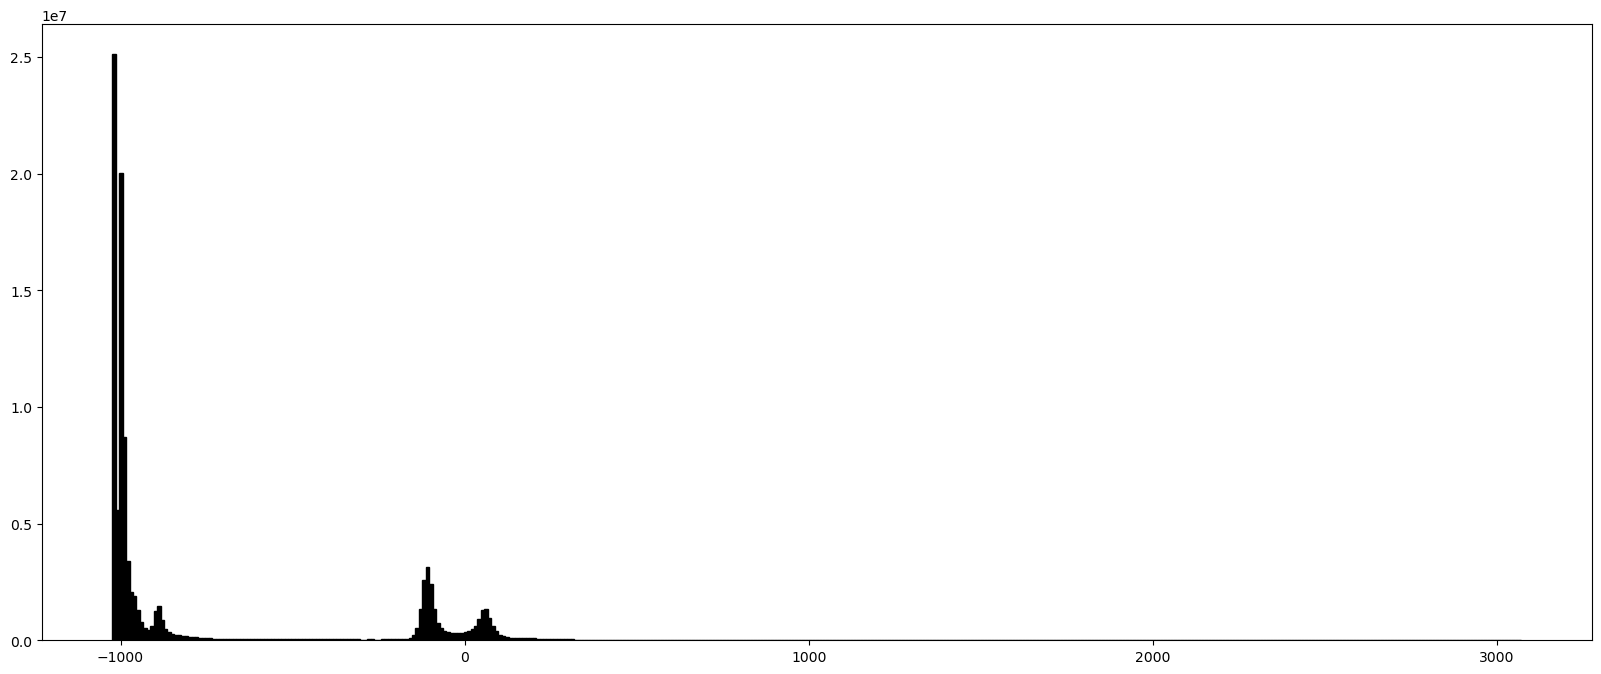

In [108]:
#plot histogram of the image
def plot_histogram(image):
    plt.figure(figsize=(20, 8))
    plt.hist(image.ravel(), bins=(1024+3071)//10, range=(-1024, 3071), fc='k', ec='k')
    plt.show()

temp2=sitk.GetArrayFromImage(sitk_image)
plot_histogram(temp2)

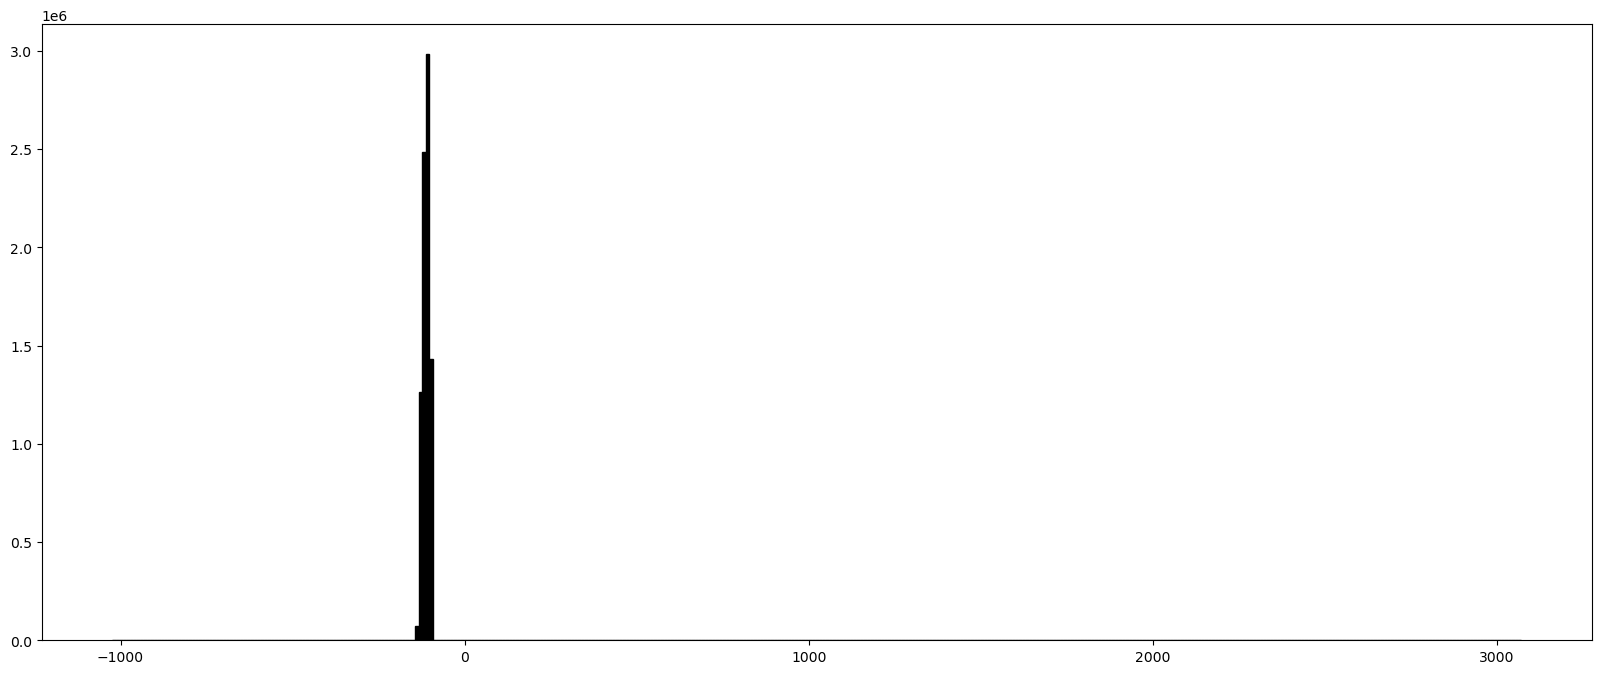

(-132.0, -97.0)

In [109]:
def get_hist_range(image):
    temp=image.ravel()
    temp=temp[temp>-1024]
    return np.percentile(temp, 1), np.percentile(temp, 99)

temp=get_region_grown(sitk_image, seed, 18)
temp=temp*(temp2+10000)-10000
plot_histogram(temp)

a,b = get_hist_range(temp)
a,b

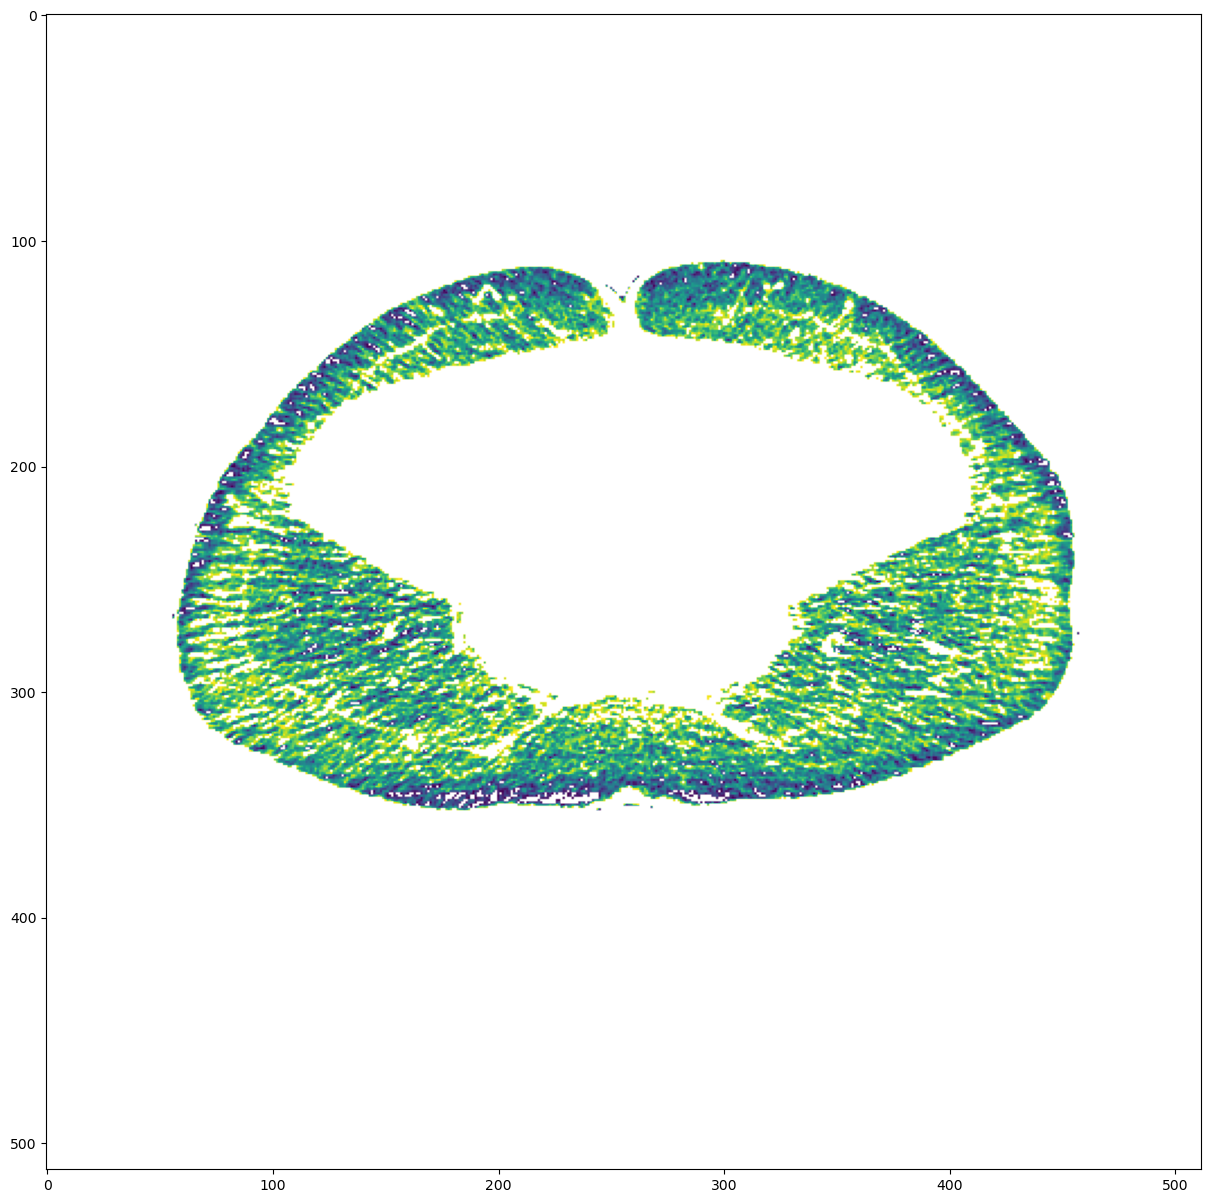

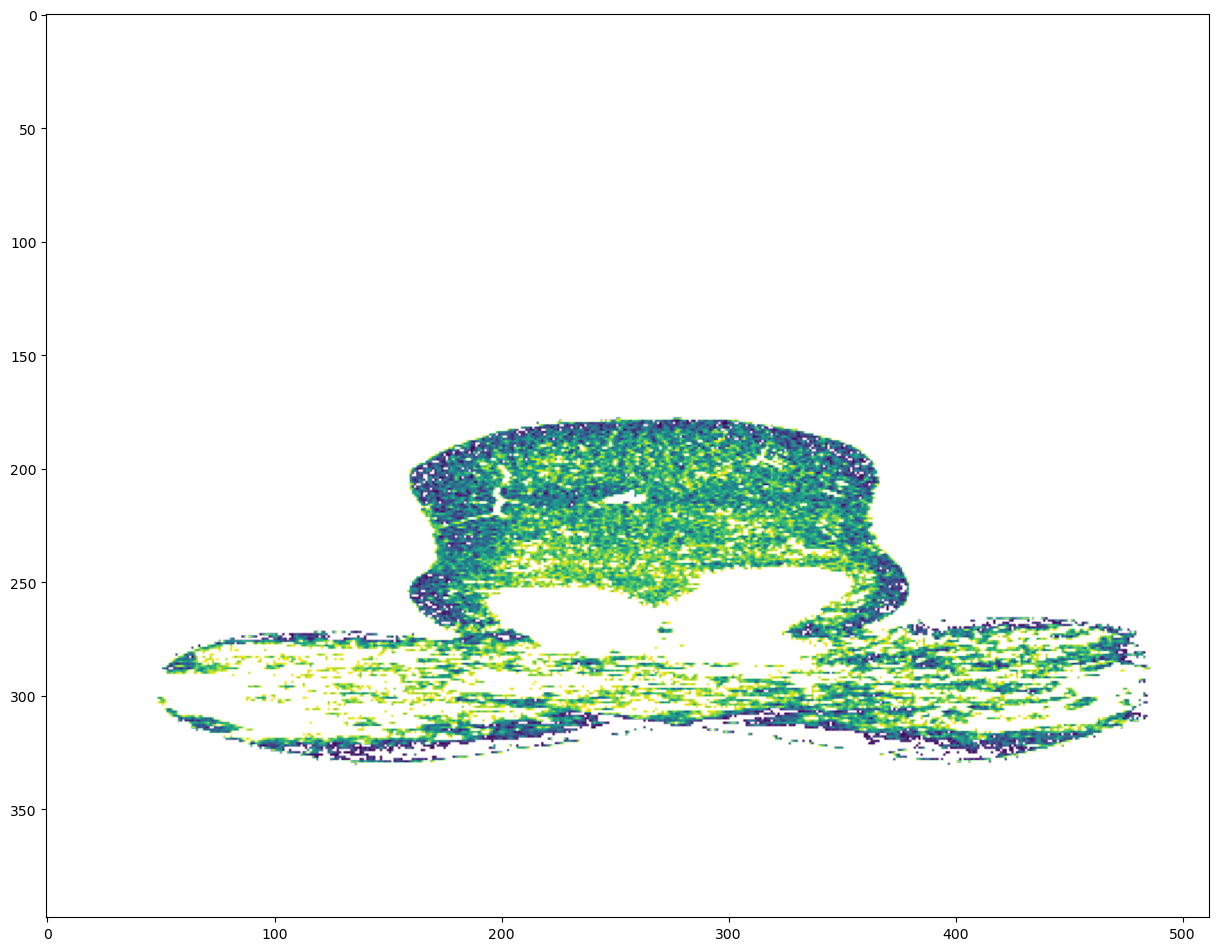

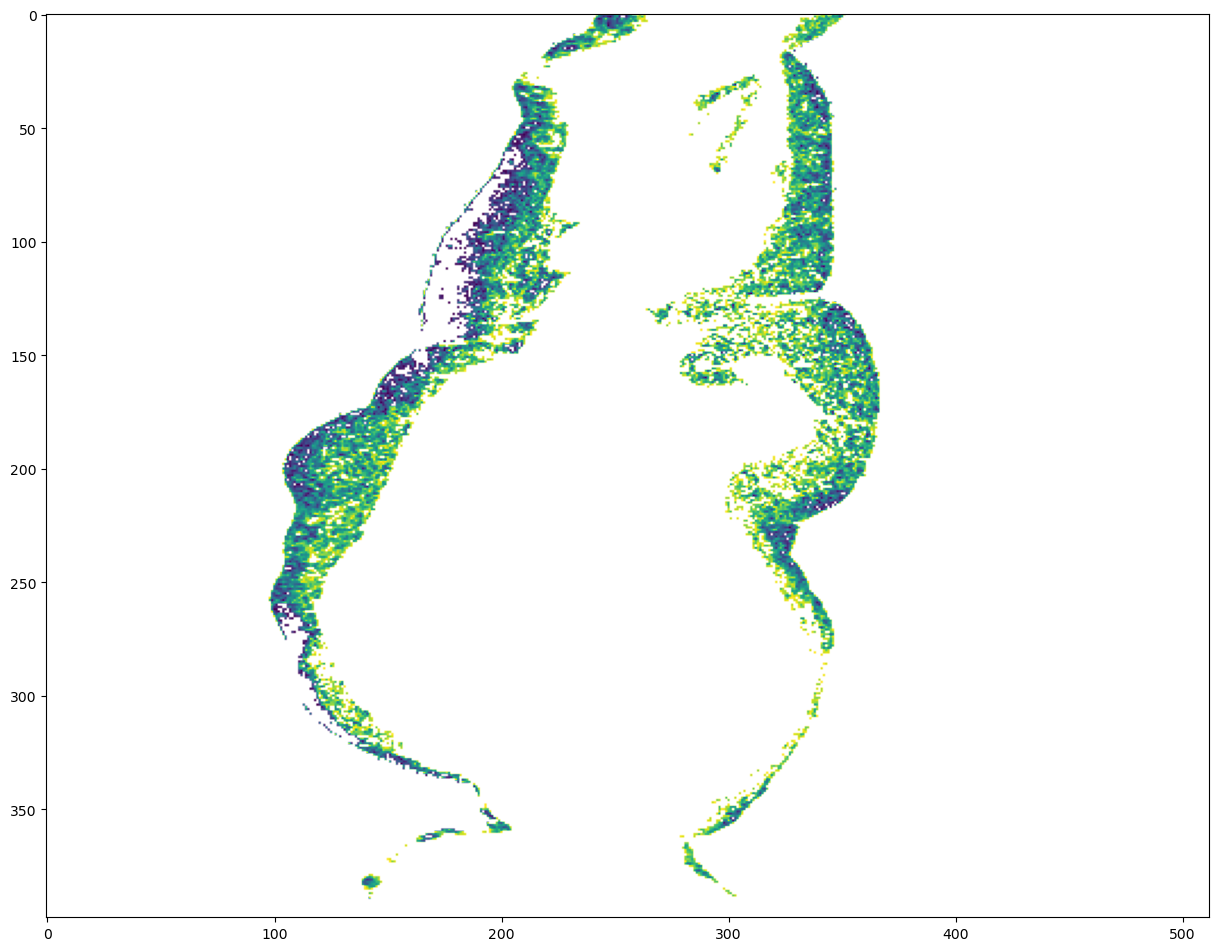

In [121]:
img = sitk.GetArrayFromImage(sitk_image)
img=np.clip(img, a, b)

temp=sitk.GetArrayFromImage(sitk_image)
temp=((temp>=a) & (temp<=b)).astype(float)
temp*=get_region_grown(sitk_image, seed, 25).astype(float)

plt.figure(figsize=(15, 15))
plt.imshow(img[seed[0],:,:], alpha=temp[seed[0],:,:])
plt.show()

plt.figure(figsize=(15, 15))
plt.imshow(img[:,seed[1]+5,:], alpha=temp[:,seed[1]+5,:])
plt.show()

plt.figure(figsize=(15, 15))
plt.imshow(img[:,:,seed[2]], alpha=temp[:,:,seed[2]])
plt.show()
